In [35]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
import ipywidgets as widgets
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": False, "grid.alpha": 0.25})

In [36]:
# Configure the datasets to compare. Add/remove entries as required:
DATASETS = {
    "01": {
        "label": "Raw",
        "root": Path("/data-fast/dragon/vicente/iongrid/runs/run_20261029_htc_cartesian/results"),
        "grid_type": "cartesian",       # "lhs" or "cartesian"
        "emission_file": "linem.fits",
        "transmission_file": "optdepth.fits",
        "emission_hdu": "SPECTRA",
        "transmission_hdu": "SPECTRA",
        "transmission_representation": "optical_depth", # Quantity stored in transmission_file (optical_depth | transmission)
    },
    "02": {
        "label": "Clean",
        "root": Path("/data-fast/dragon/vicente/iongrid/runs/run_20261029_htc_cartesian/results"),
        "grid_type": "cartesian",             # "lhs" or "cartesian"
        "emission_file": "linem_clean.fits",
        "transmission_file": "optdepth_clean.fits",
        "emission_hdu": "SPECTRA",
        "transmission_hdu": "SPECTRA",
        "transmission_representation": "optical_depth",
    },
}

# Optional overrides for unusual FITS layouts:
PARAMS_HDU = "PARAMS"
ENERGY_HDU = "ENERGY"
GRID_HDU = "GRID"

# Parameter matching and random examples:
MATCH_DECIMALS = 5
N_RANDOM_SPECTRA = 20
RANDOM_SEED = 12345

# Energy interval used for plots (keV):
ENERGY_LOW_LIM = 0.1
ENERGY_UP_LIM = 12.0

# Reference dataset used to initialize the interactive parameter explorers:
REFERENCE_DATASET = None  # None = first dataset in DATASETS

# Figure output:
SAVE_FIGURES = False
OUTPUT_DIR = Path("./xstar_stacked_comparisons")

# Metadata columns excluded from physical-parameter matching/exploration.
EXCLUDED_PARAMETERS = {"point_id", "grid_id", "population", "model_id", "simulation_id", "id", "index"}

# Aliases used to recognize equivalent parameter names across files.
PARAMETER_ALIASES = {
    "nh": "lognh", "n_h": "lognh", "log_nh": "lognh", "lognh": "lognh", 
    "xi": "logxi", "log_xi": "logxi", "logxi": "logxi",
    "v_turb": "vturb", "vturb": "vturb",
    "gamma_sed": "gamma", "gamma": "gamma",
    "fe_abund": "feabund", "iron_abundance": "feabund", "feabund": "feabund",
    "log_lum": "loglum", "loglum": "loglum", "lum": "luminosity", "luminosity": "luminosity",
    "density": "density", "log_n": "logn",
}

print(f"Configured {len(DATASETS)} datasets: {[v['label'] for v in DATASETS.values()]}")

Configured 2 datasets: ['Raw', 'Clean']


In [37]:
# Helper functions:
def _clean_name(name):
    """Normalize a parameter name for matching while retaining original names for display."""
    key = str(name).strip().lower()
    key = re.sub(r"[^a-z0-9]+", "_", key).strip("_")
    return PARAMETER_ALIASES.get(key, key)

def _native_array(values):
    """Convert FITS big-endian numeric arrays to native byte order."""
    arr = np.asarray(values)
    if arr.dtype.kind in "biufc" and arr.dtype.byteorder == ">":
        arr = arr.astype(arr.dtype.newbyteorder("="), copy=True)
    return arr

def _energy_to_kev(energy):
    """Convert eV to keV using the convention requested for these stacked files."""
    energy = np.asarray(energy, dtype=float).reshape(-1)
    finite = energy[np.isfinite(energy)]
    if finite.size == 0:
        raise ValueError("Energy array contains no finite values.")
    return energy / 1000.0 if np.nanmin(finite) > 1e-2 else energy.copy()

def _parameter_frame_from_lhs(hdul):
    data = hdul[PARAMS_HDU].data
    if data is None or data.names is None:
        raise ValueError(f"{PARAMS_HDU} is not a named FITS table.")
    frame = pd.DataFrame({name: _native_array(data[name]).reshape(-1) for name in data.names})
    units = {name: (hdul[PARAMS_HDU].columns[name].unit or "") for name in data.names}
    return frame, units

def _parameter_frame_from_cartesian(hdul):
    grid_hdu = hdul[GRID_HDU]
    names = list(grid_hdu.columns.names)
    if len(names) < 2:
        raise ValueError("Cartesian GRID extension must contain ENERGY and parameter axes.")
    energy = _native_array(grid_hdu.data[names[0]][0]).reshape(-1)
    parameter_names = names[1:]
    axes = [_native_array(grid_hdu.data[name][0]).reshape(-1) for name in parameter_names]
    mesh = np.meshgrid(*axes, indexing="ij")
    frame = pd.DataFrame({name: values.ravel() for name, values in zip(parameter_names, mesh)})
    units = {name: (grid_hdu.columns[name].unit or "") for name in parameter_names}
    return frame, units, energy

def _reshape_spectra(raw, n_models, n_energy, component_name):
    arr = np.asarray(raw, dtype=float)
    if arr.ndim == 1:
        if n_models == 1 and arr.size == n_energy:
            arr = arr.reshape(1, n_energy)
        else:
            raise ValueError(f"{component_name}: unexpected 1-D spectra array of length {arr.size}.")
    if arr.shape == (n_models, n_energy):
        return arr
    if arr.size == n_models * n_energy:
        return arr.reshape(n_models, n_energy)
    raise ValueError(f"{component_name}: cannot reshape spectra with shape {arr.shape} to ({n_models}, {n_energy}). Check FITS axis ordering and grid metadata.")

def _load_component(path, grid_type, spectra_hdu, component_name):
    with fits.open(path, memmap=False) as hdul:
        if grid_type == "lhs":
            params, units = _parameter_frame_from_lhs(hdul)
            energy = _native_array(hdul[ENERGY_HDU].data).reshape(-1)
        elif grid_type == "cartesian":
            params, units, energy = _parameter_frame_from_cartesian(hdul)
        else:
            raise ValueError(f"Unknown grid_type={grid_type!r}; use 'lhs' or 'cartesian'.")
        raw_spectra = _native_array(hdul[spectra_hdu].data)
        energy_kev = _energy_to_kev(energy)
        spectra = _reshape_spectra(raw_spectra, len(params), len(energy_kev), component_name)
    params = params.reset_index(drop=True)
    for col in params.columns:
        try:
            params[col] = pd.to_numeric(params[col])
        except (ValueError, TypeError):
            pass
    return {"params": params, "units": units, "energy": energy_kev, "spectra": np.asarray(spectra, dtype=float), "path": path}

def _check_emission_transmission_alignment(dataset_id, emission, transmission):
    """Check that both components describe the same rows on the same energy grid."""
    if len(emission["params"]) != len(transmission["params"]):
        raise ValueError(f"{dataset_id}: emission and transmission contain different numbers of parameter rows.")
    if len(emission["energy"]) != len(transmission["energy"]) or not np.allclose(
        emission["energy"],
        transmission["energy"],
        rtol=1e-10,
        atol=1e-12,
        equal_nan=True,
    ):
        raise ValueError(f"{dataset_id}: emission and transmission energy arrays are not identical. This notebook assumes a shared energy grid."
        )
    emission_schema = {}
    transmission_schema = {}
    for column in physical_columns(emission["params"]):
        canonical = _clean_name(column)
        if canonical in emission_schema:
            raise ValueError(f"{dataset_id}: multiple emission columns map to parameter {canonical!r}.")
        emission_schema[canonical] = column
    for column in physical_columns(transmission["params"]):
        canonical = _clean_name(column)
        if canonical in transmission_schema:
            raise ValueError(f"{dataset_id}: multiple transmission columns map to parameter {canonical!r}.")
        transmission_schema[canonical] = column
    if set(emission_schema) != set(transmission_schema):
        only_emission = sorted(set(emission_schema) - set(transmission_schema))
        only_transmission = sorted(set(transmission_schema) - set(emission_schema))
        raise ValueError(f"{dataset_id}: emission and transmission parameter columns differ. Only in emission: {only_emission}; only in transmission: {only_transmission}.")
    for canonical, emission_column in emission_schema.items():
        transmission_column = transmission_schema[canonical]
        emission_values = emission["params"][emission_column].to_numpy()
        transmission_values = transmission["params"][transmission_column].to_numpy()
        try:
            same = np.allclose(
                np.asarray(emission_values, dtype=float),
                np.asarray(transmission_values, dtype=float),
                rtol=1e-10,
                atol=1e-12,
                equal_nan=True,
            )
        except (TypeError, ValueError):
            emission_text = (pd.Series(emission_values).astype("string").fillna("<NA>").to_numpy())
            transmission_text = (pd.Series(transmission_values).astype("string").fillna("<NA>").to_numpy())
            same = np.array_equal(emission_text, transmission_text)
        if not same:
            raise ValueError(f"{dataset_id}: emission and transmission values for parameter {canonical!r} do not match row by row. The joint comparison would associate different simulations.")

def load_dataset(dataset_id, cfg):
    root = Path(cfg["root"])
    em_path = root / cfg["emission_file"]
    tr_path = root / cfg["transmission_file"]
    for path in (em_path, tr_path):
        if not path.exists():
            raise FileNotFoundError(f"{dataset_id} ({cfg['label']}): file not found: {path}")
    emission = _load_component(em_path, cfg["grid_type"], cfg.get("emission_hdu", "SPECTRA"), "emission")
    transmission = _load_component(tr_path, cfg["grid_type"], cfg.get("transmission_hdu", "SPECTRA"), "transmission")
    representation = str(cfg.get("transmission_representation", "optical_depth")).strip().lower()
    if representation in {"optical_depth", "tau", "optdepth"}:
        raw_tau = np.asarray(transmission["spectra"], dtype=float)
        with np.errstate(over="ignore", invalid="ignore"):
            transmission["spectra"] = np.exp(-raw_tau)
        transmission["input_representation"] = "optical_depth"
        transmission["conversion"] = "T(E) = exp[-tau(E)]"
    elif representation in {"transmission", "transmitted_fraction", "fraction"}:
        # The file already contains T(E): do not apply exp(-x) again.
        transmission["spectra"] = np.asarray(transmission["spectra"], dtype=float)
        transmission["input_representation"] = "transmission"
        transmission["conversion"] = "none; input used directly"
        finite_values = transmission["spectra"][np.isfinite(transmission["spectra"])]
        if finite_values.size:
            vmin, vmax = float(np.nanmin(finite_values)), float(np.nanmax(finite_values))
            source_name = Path(tr_path).name.lower()
            if any(token in source_name for token in ("optdepth", "optical_depth", "tau")):
                warnings.warn(
                    f"{dataset_id}: transmission_representation='transmission' but "
                    f"the source filename {tr_path.name!r} suggests optical depth. "
                    "Verify the actual FITS contents. If the array contains tau(E), "
                    "select transmission_representation='optical_depth' so it is "
                    "converted to exp[-tau(E)].",
                    RuntimeWarning)
            # A transmission fraction is normally bounded between zero and one. Warn rather than silently clipping because this may indicate that an optical-depth file was selected with the wrong setting.
            if vmin < -1e-6 or vmax > 1.0 + 1e-6:
                warnings.warn(
                    f"{dataset_id}: transmission_representation='transmission', but "
                    f"the loaded values span [{vmin:.4g}, {vmax:.4g}], outside "
                    "the usual [0, 1] range. Check that transmission_file really "
                    "contains T(E), not optical depth tau(E). If it contains tau, "
                    "set transmission_representation='optical_depth'.",
                    RuntimeWarning,
                )
    else:
        raise ValueError(f"{dataset_id}: transmission_representation must be 'optical_depth' or 'transmission'.")
    print(f"{dataset_id}: transmission input = {transmission['input_representation']} ({transmission['conversion']}); file = {tr_path.name}")
    # Both components must be row-aligned and use the same energy grid:
    _check_emission_transmission_alignment(dataset_id, emission, transmission)
    return {"id": dataset_id,  "label": cfg["label"], "cfg": cfg, "emission": emission, "transmission": transmission}

def save_or_show(fig, filename):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, bbox_inches="tight")
    plt.show()

def format_value(value):
    if isinstance(value, (float, np.floating)):
        return f"{value:.4g}"
    return str(value)

def physical_columns(frame):
    return [c for c in frame.columns if str(c).strip().lower() not in EXCLUDED_PARAMETERS]


In [38]:
dataset_ids = list(DATASETS)
if len(dataset_ids) < 2:
    raise ValueError("Configure at least two datasets to compare.")
if REFERENCE_DATASET is None:
    reference_id = dataset_ids[0]
else:
    if REFERENCE_DATASET not in DATASETS:
        raise KeyError(f"REFERENCE_DATASET={REFERENCE_DATASET!r} is not configured.")
    reference_id = REFERENCE_DATASET
grids = {key: load_dataset(key, DATASETS[key]) for key in dataset_ids}

for key, data in grids.items():
    shared = data["emission"]
    print(f"\\n{data['label']} ({key})")
    print(
        f"  {len(shared['params']):,} models, "
        f"{len(shared['energy']):,} energy bins, "
        f"range {np.nanmin(shared['energy']):.4g}–{np.nanmax(shared['energy']):.4g} keV"
    )
    print(f"  shared parameter columns: {list(shared['params'].columns)}")
    print("  emission/transmission parameter rows and energy arrays: aligned")
    trans_values = data["transmission"]["spectra"]
    finite_trans = trans_values[np.isfinite(trans_values)]
    if finite_trans.size:
        print(f"  plotted transmission range: [{np.nanmin(finite_trans):.4g}, {np.nanmax(finite_trans):.4g}]")
        
print(f"\\nResidual reference: {grids[reference_id]['label']}")


01: transmission input = optical_depth (T(E) = exp[-tau(E)]); file = optdepth.fits
02: transmission input = optical_depth (T(E) = exp[-tau(E)]); file = optdepth_clean.fits
\nRaw (01)
  32 models, 9,999 energy bins, range 0.0001–1005 keV
  shared parameter columns: ['LOGXI', 'VTURB', 'LOG_NH', 'FEABUND', 'GAMMA']
  emission/transmission parameter rows and energy arrays: aligned
  plotted transmission range: [1.323e-21, 1]
\nClean (02)
  32 models, 9,999 energy bins, range 0.0001–1005 keV
  shared parameter columns: ['LOGXI', 'VTURB', 'LOG_NH', 'FEABUND', 'GAMMA']
  emission/transmission parameter rows and energy arrays: aligned
  plotted transmission range: [1.323e-21, 1]
\nResidual reference: Raw


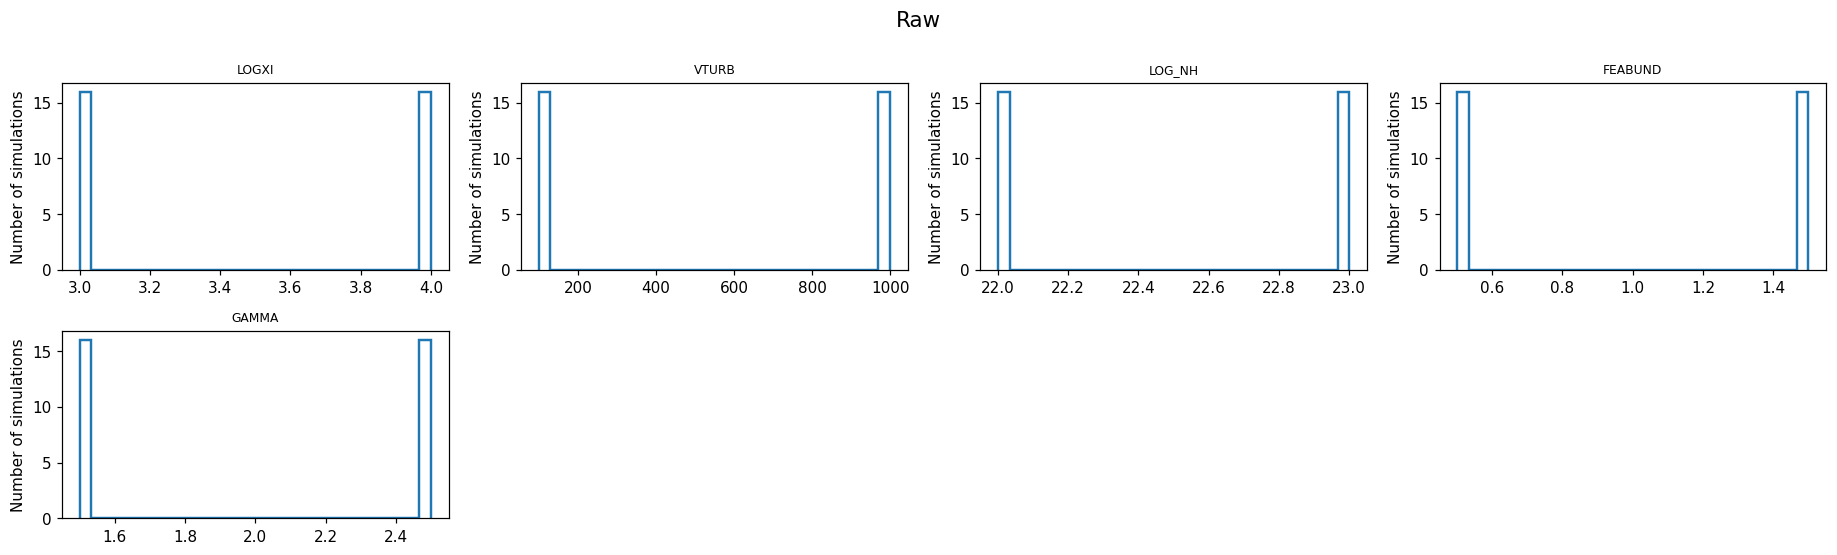

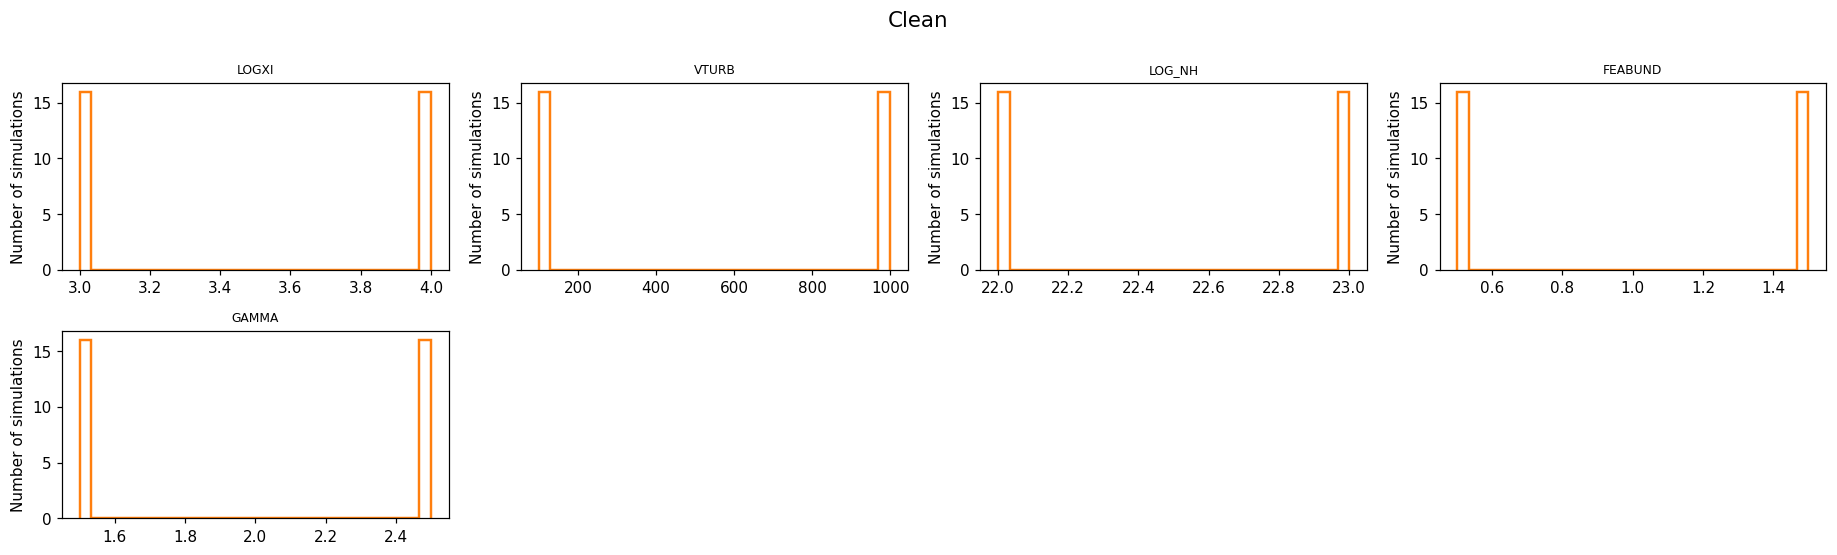

In [40]:
# Plot parameter distributions:
default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
dataset_colors = {key: default_colors[i % len(default_colors)] for i, key in enumerate(dataset_ids)}

for key in dataset_ids:
    dataset_label = grids[key]["label"]
    params = grids[key]["emission"]["params"]
    parameter_names = physical_columns(params)
    if not parameter_names:
        print(f"No physical parameters found for {dataset_label}.")
        continue
    # Build figure:
    ncols = min(4, len(parameter_names))
    nrows = int(np.ceil(len(parameter_names) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 2.5 * nrows), squeeze=False)
    for i, name in enumerate(parameter_names):
        ax = axs.flat[i]
        values = pd.to_numeric(params[name], errors="coerce").dropna()
        ax.hist(values, bins=30, histtype="step", linewidth=1.6, color=dataset_colors[key])
        ax.set_title(name, fontsize = 8)
        ax.set_ylabel("Number of simulations")
    for ax in axs.flat[len(parameter_names):]:
        ax.axis("off")
    fig.suptitle(f"{dataset_label}", y=1.0, fontsize = 14)
    fig.tight_layout()
    save_or_show(fig, f"{key}_parameter_distributions.png")


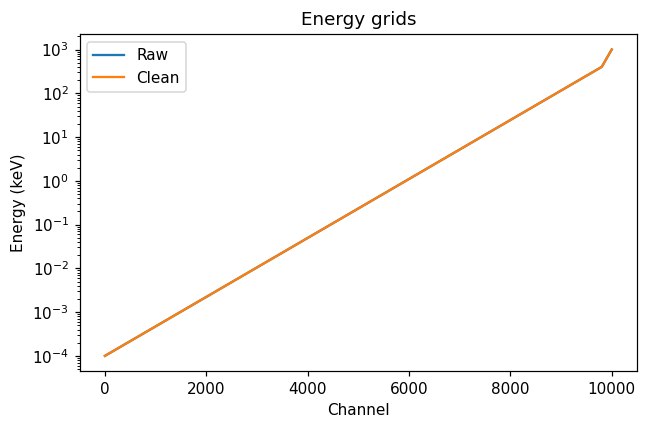

In [42]:
# Compare the shared energy grids:
fig, ax = plt.subplots(figsize=(6.0, 4.0))
for key in dataset_ids:
    energy = grids[key]["emission"]["energy"]
    ax.plot(np.arange(len(energy)), energy, color=dataset_colors[key], linewidth=1.5, label=grids[key]["label"])
ax.set_yscale("log")
ax.set_xlabel("Channel")
ax.set_ylabel("Energy (keV)")
ax.set_title("Energy grids")
ax.legend()
fig.tight_layout()
save_or_show(fig, "energy_grids.png")

In [43]:
# Match simulations accross datasets:
def component_parameter_schema(component, dataset_id):
    return grids[dataset_id][component]["params"]

def common_physical_columns(component):
    schemas = [
        {_clean_name(c): c for c in physical_columns(component_parameter_schema(component, key))}
        for key in dataset_ids
    ]
    common = set(schemas[0])
    for schema in schemas[1:]:
        common &= set(schema)
    # Preserve the reference dataset's parameter order:
    ordered = []
    for canonical in schemas[0]:
        if canonical in common:
            ordered.append(canonical)
    if not ordered:
        raise ValueError(f"No common physical parameters found across datasets for {component}.")
    return ordered, schemas

def make_parameter_keys(frame, schema, canonical_names, decimals=MATCH_DECIMALS):
    """Rounded physical-parameter tuples, independent of metadata/row IDs."""
    keys = []
    for _, row in frame.iterrows():
        values = []
        for canonical in canonical_names:
            original = schema[canonical]
            value = row[original]
            if pd.isna(value):
                values.append(("nan",))
            elif isinstance(value, (int, float, np.number)):
                values.append(round(float(value), decimals))
            else:
                values.append(str(value))
        keys.append(tuple(values))
    return keys

def match_component(component, decimals=MATCH_DECIMALS):
    canonical_names, schemas = common_physical_columns(component)
    maps = []
    key_sets = []
    for key in dataset_ids:
        frame = grids[key][component]["params"]
        row_keys = make_parameter_keys(
            frame, schemas[dataset_ids.index(key)], canonical_names, decimals
        )
        mapping = {}
        for idx, row_key in enumerate(row_keys):
            mapping.setdefault(row_key, idx)
        maps.append(mapping)
        key_sets.append(set(mapping))
    common_keys = sorted(set.intersection(*key_sets))
    if not common_keys:
        raise ValueError(f"No matched {component} simulations. Check parameter names, units, parameter transformations and MATCH_DECIMALS.")
    indices = {
        key: np.asarray([maps[i][row_key] for row_key in common_keys], dtype=int)
        for i, key in enumerate(dataset_ids)
    }
    return {
        "canonical_names": canonical_names,
        "schemas": schemas,
        "keys": common_keys,
        "indices": indices,
    }

# Parameters are shared by emission and transmission, so matching is done once:
matches = match_component("emission")
print(f"{len(matches['keys']):,} common parameter combinations across {len(dataset_ids)} datasets.")
print("Matched parameters:", matches["canonical_names"])


32 common parameter combinations across 2 datasets.
Matched parameters: ['logxi', 'vturb', 'lognh', 'feabund', 'gamma']


All datasets share the same energy grid: residual panels will be shown (direct bin-by-bin differences; no interpolation).


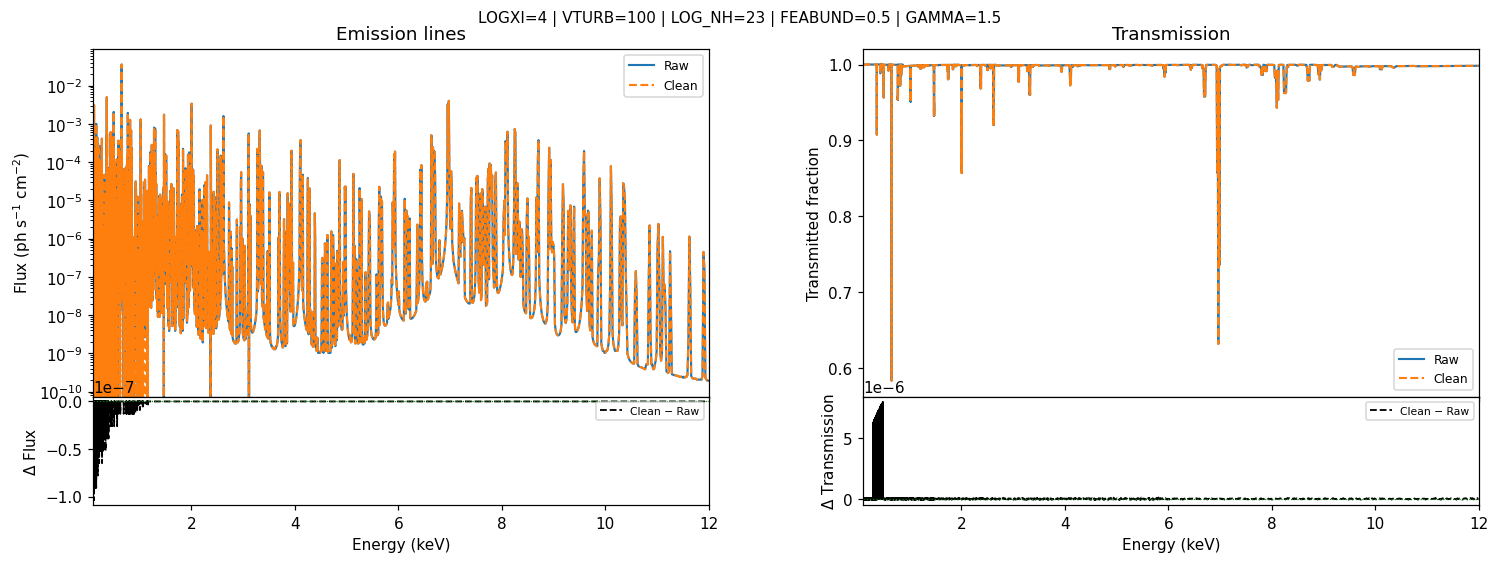

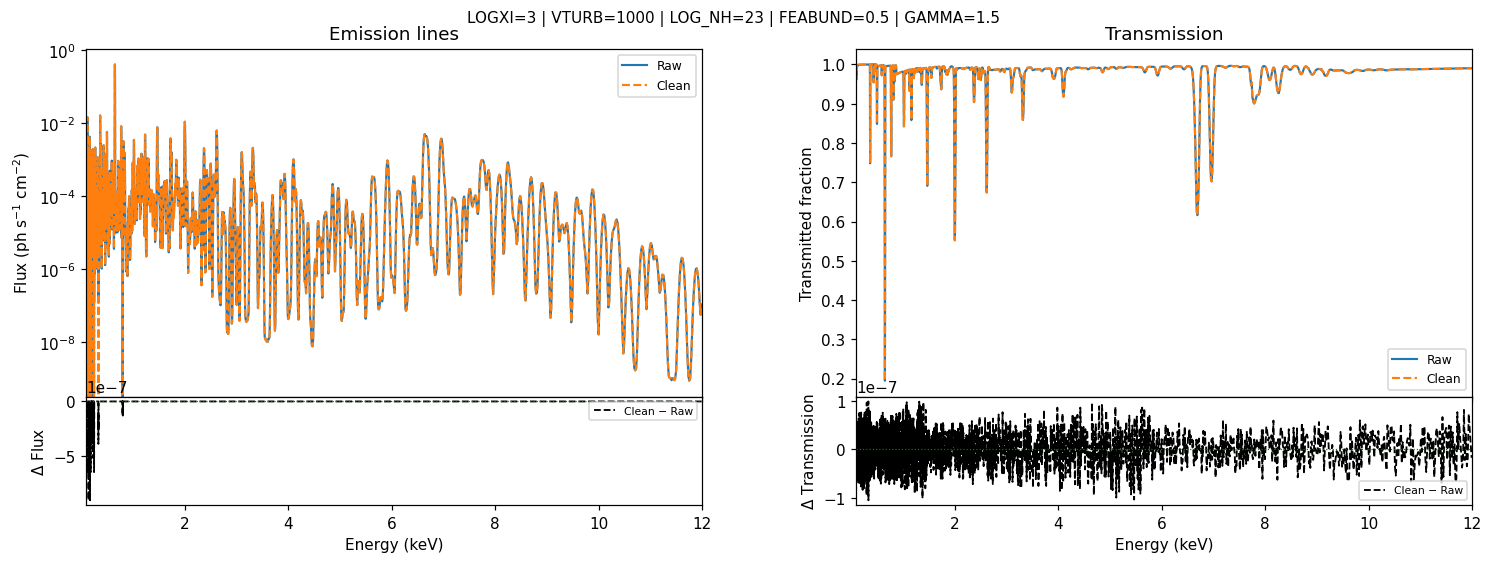

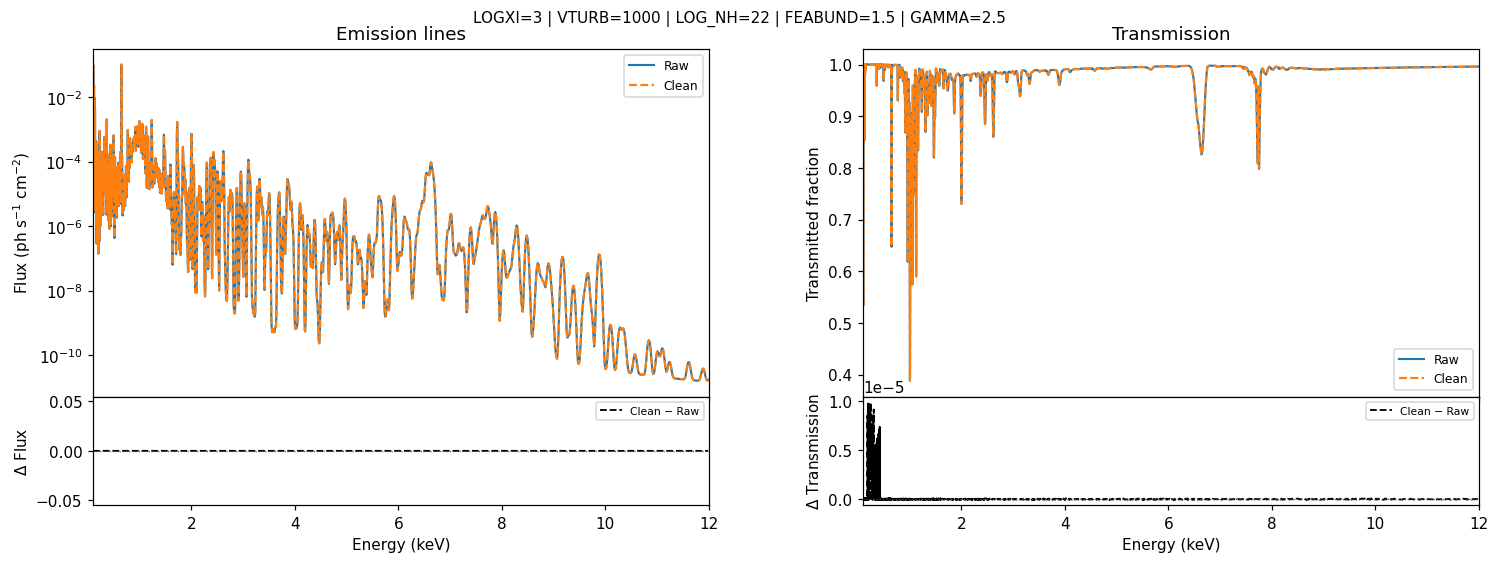

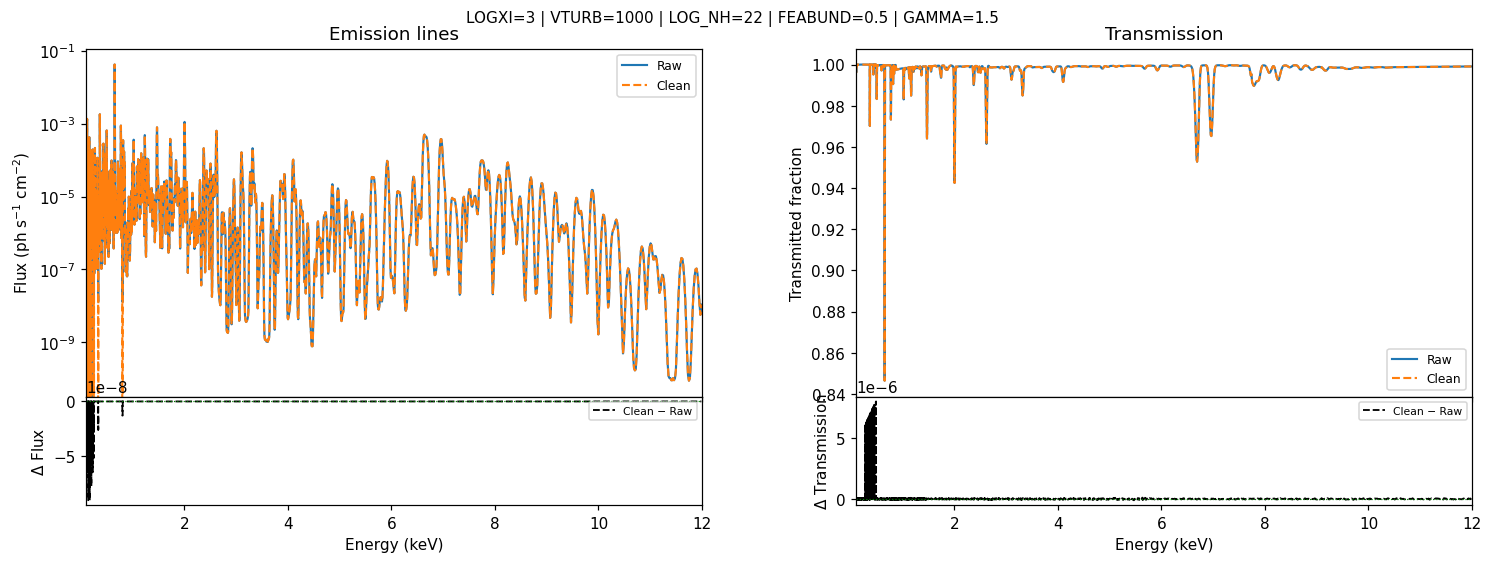

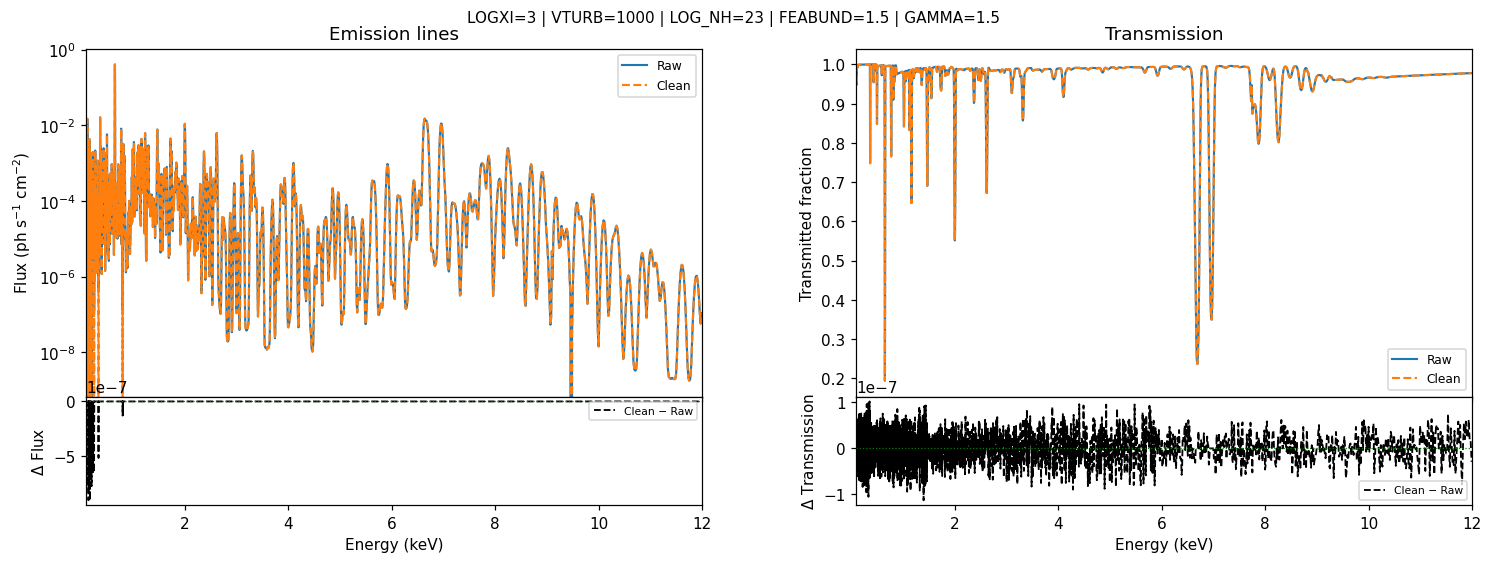

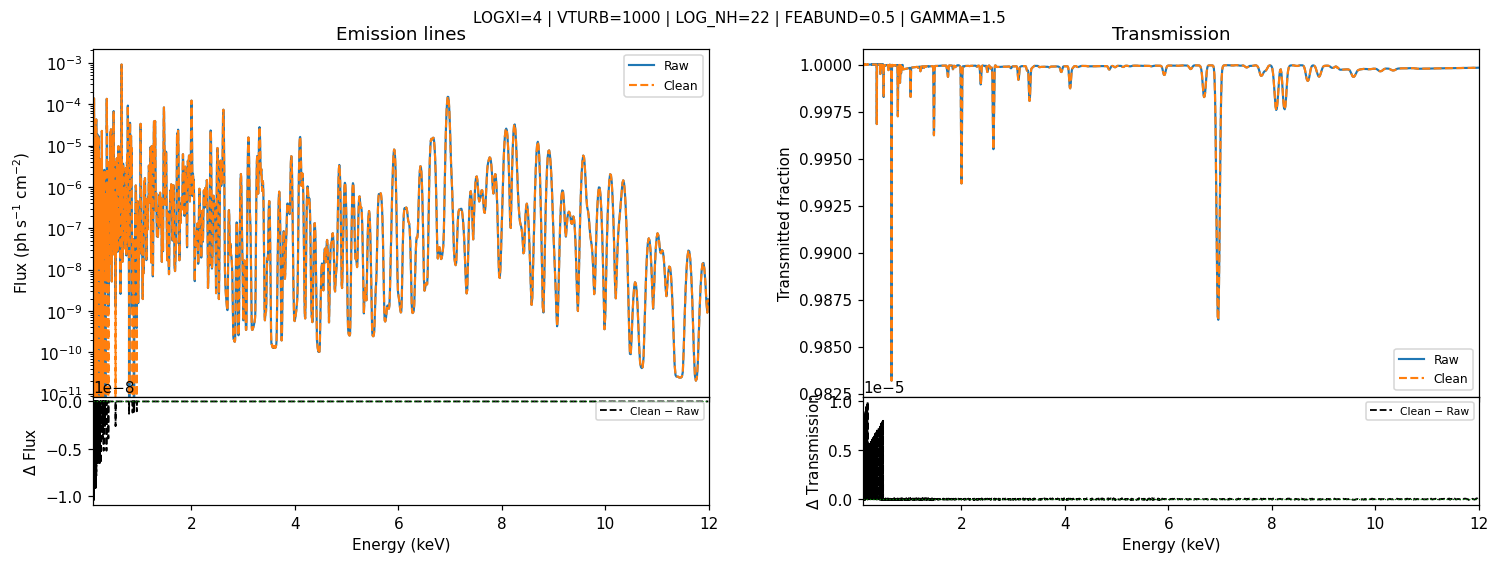

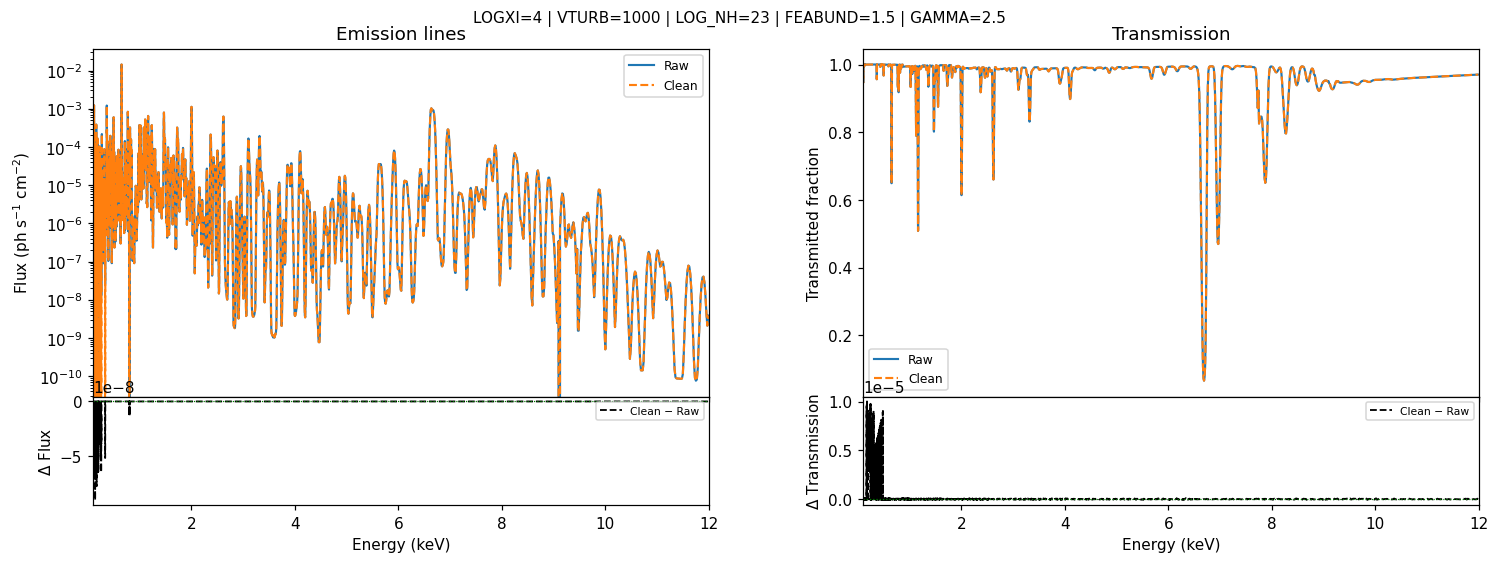

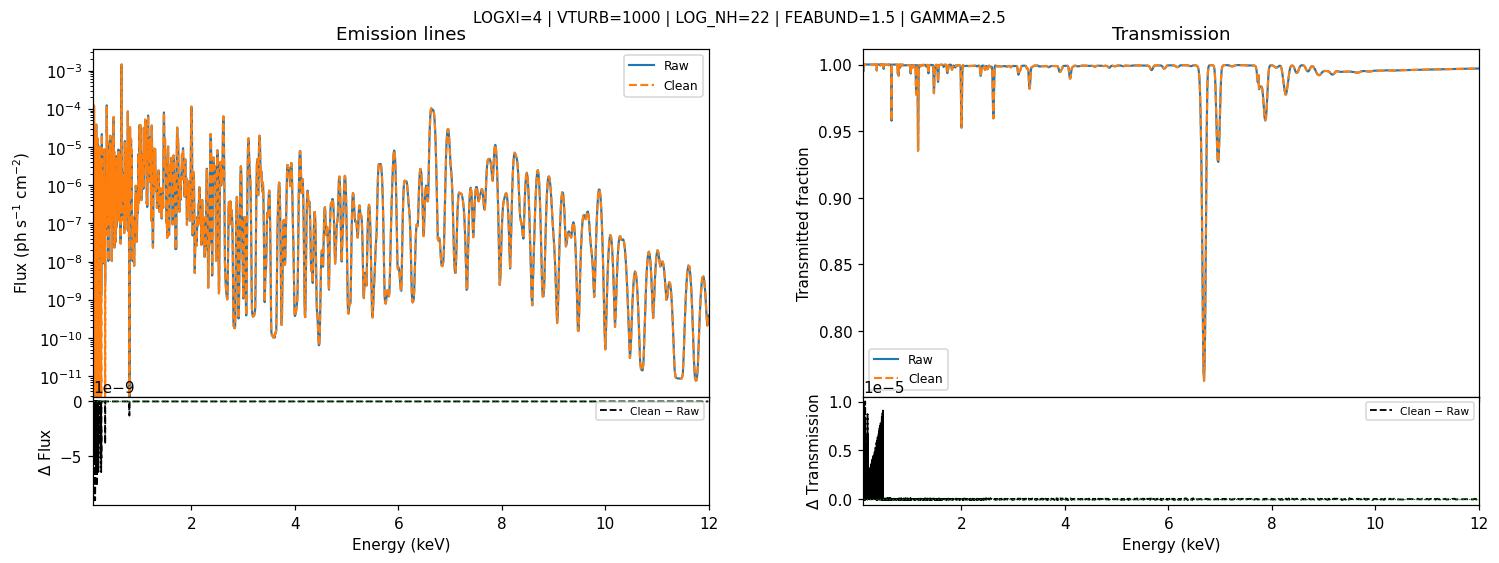

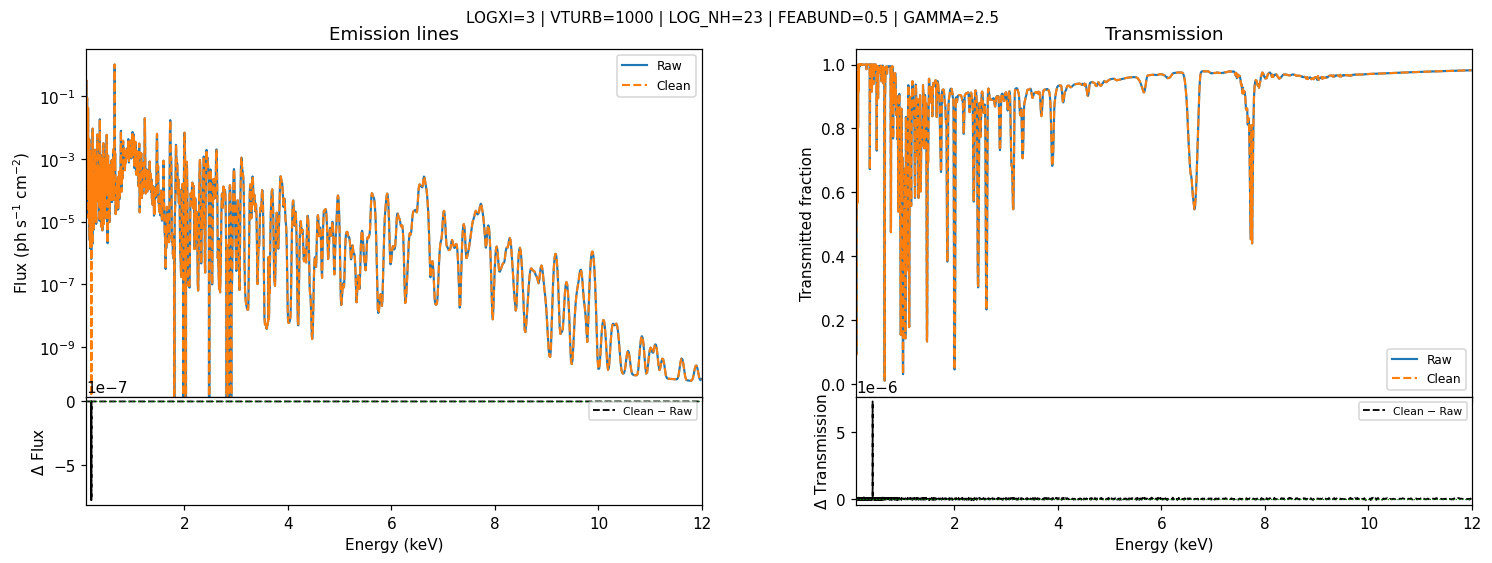

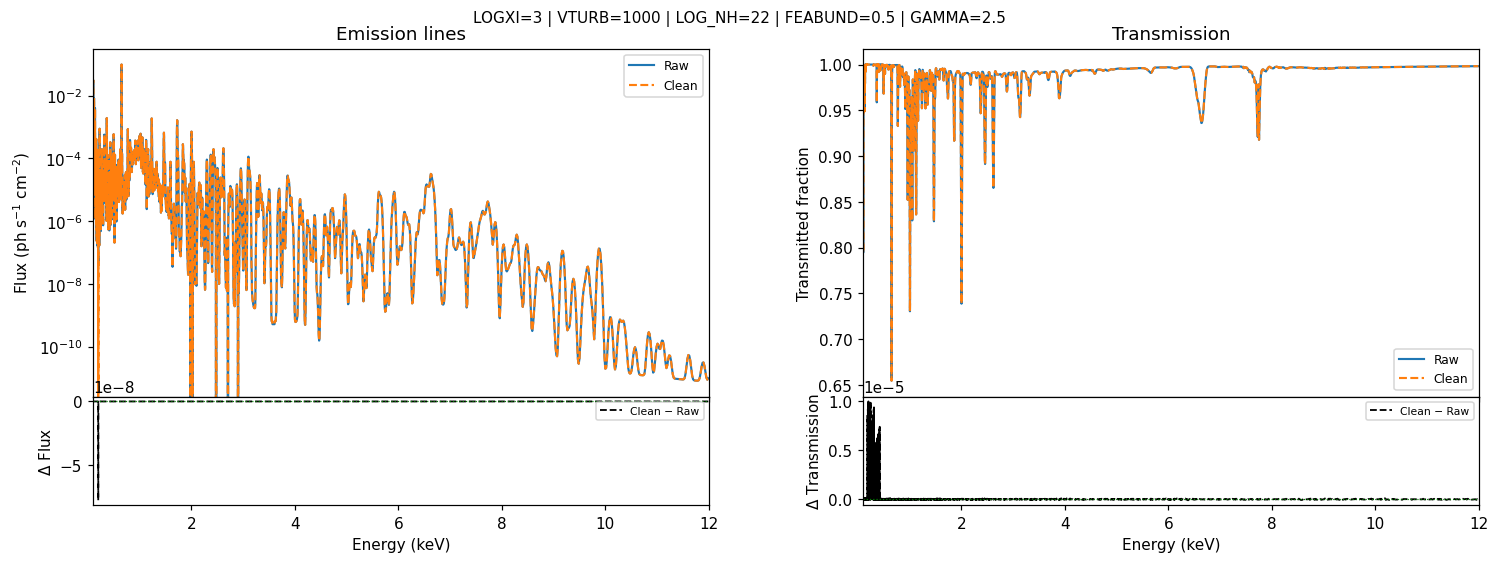

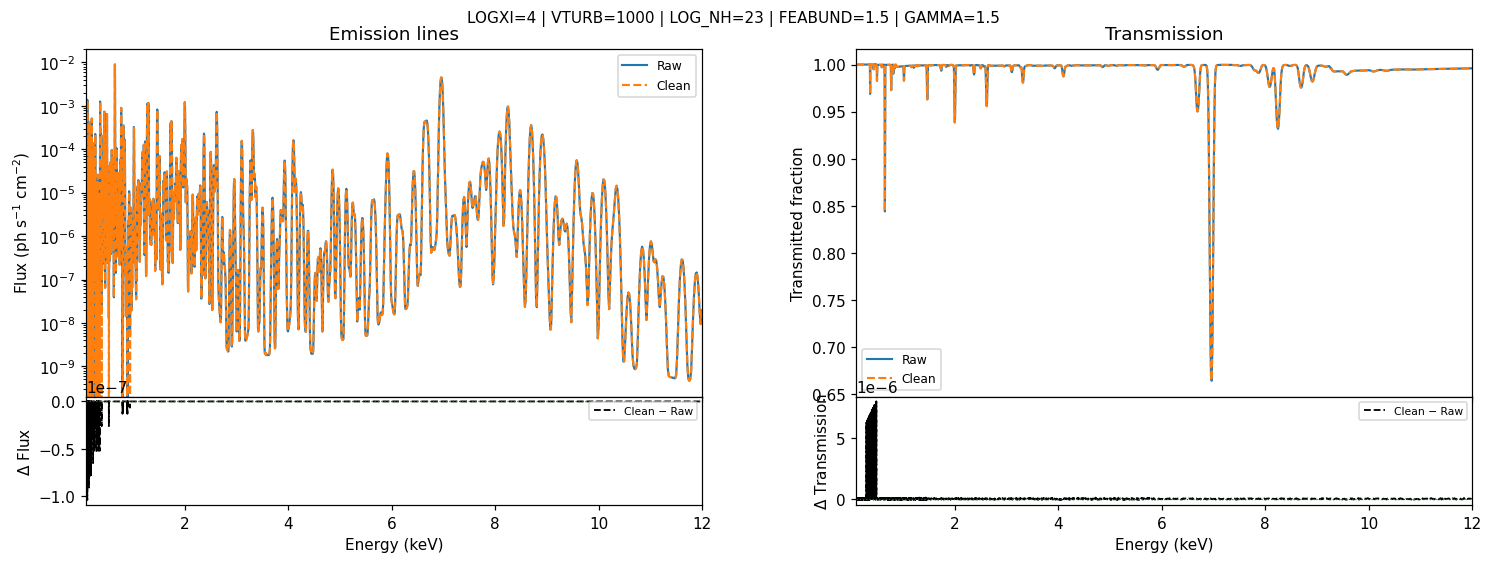

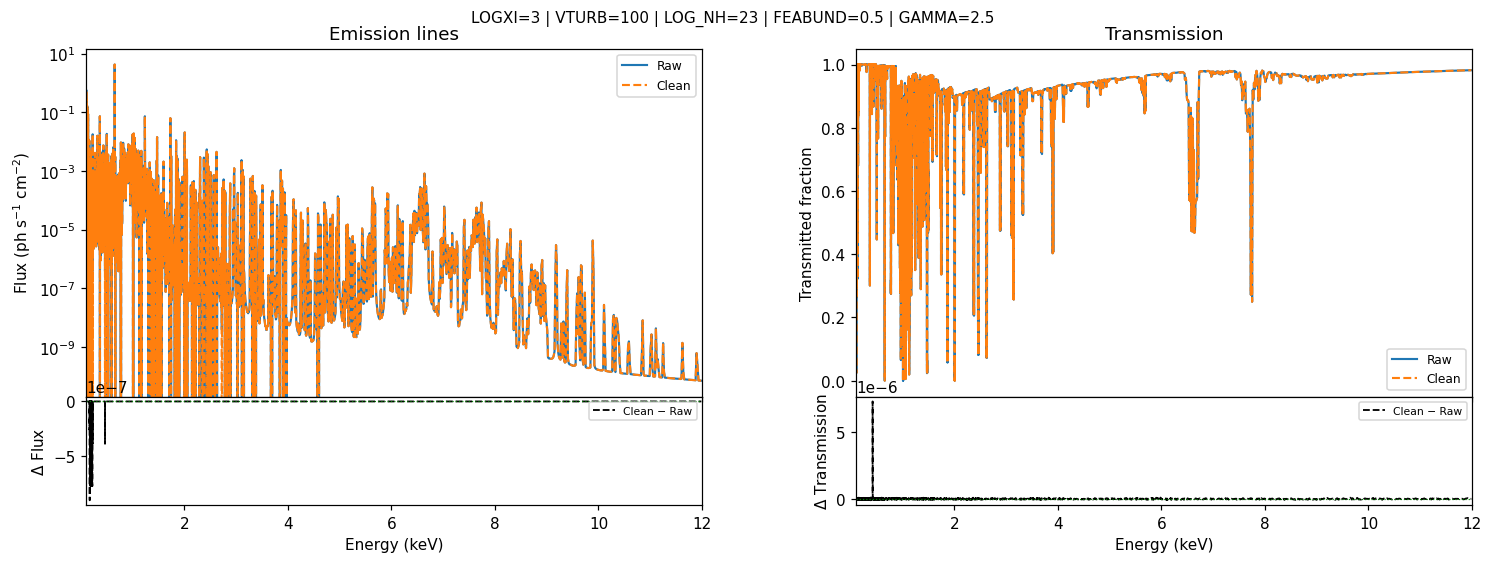

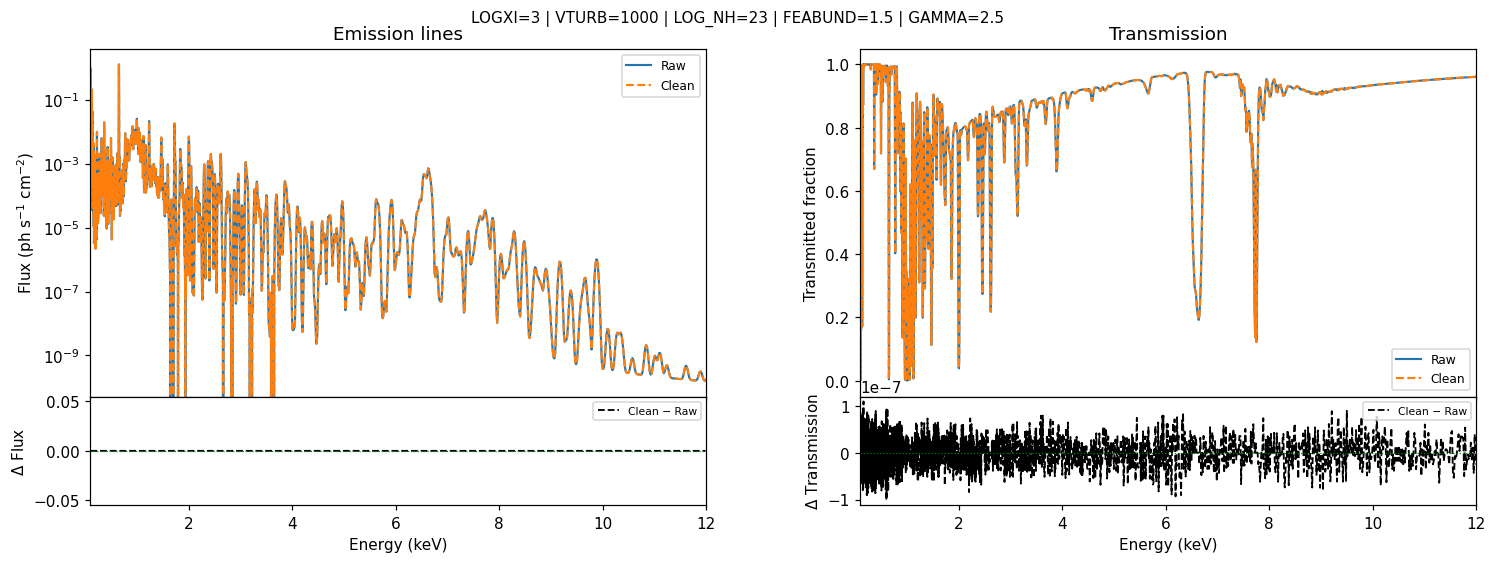

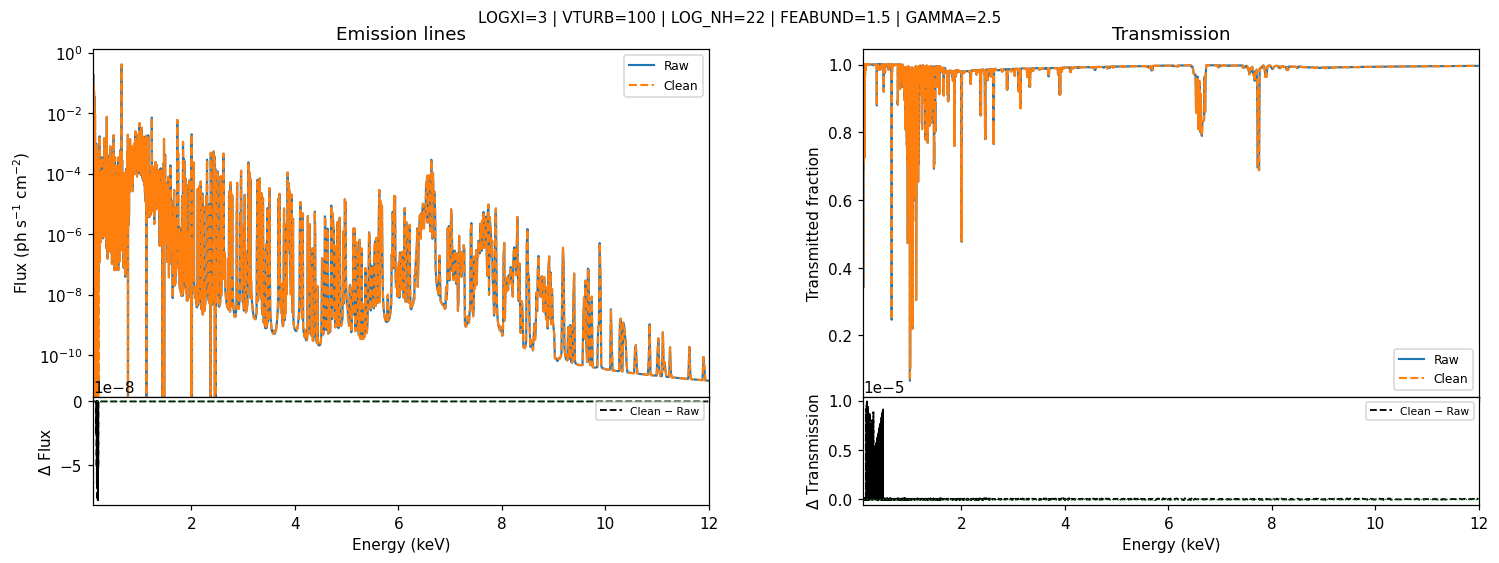

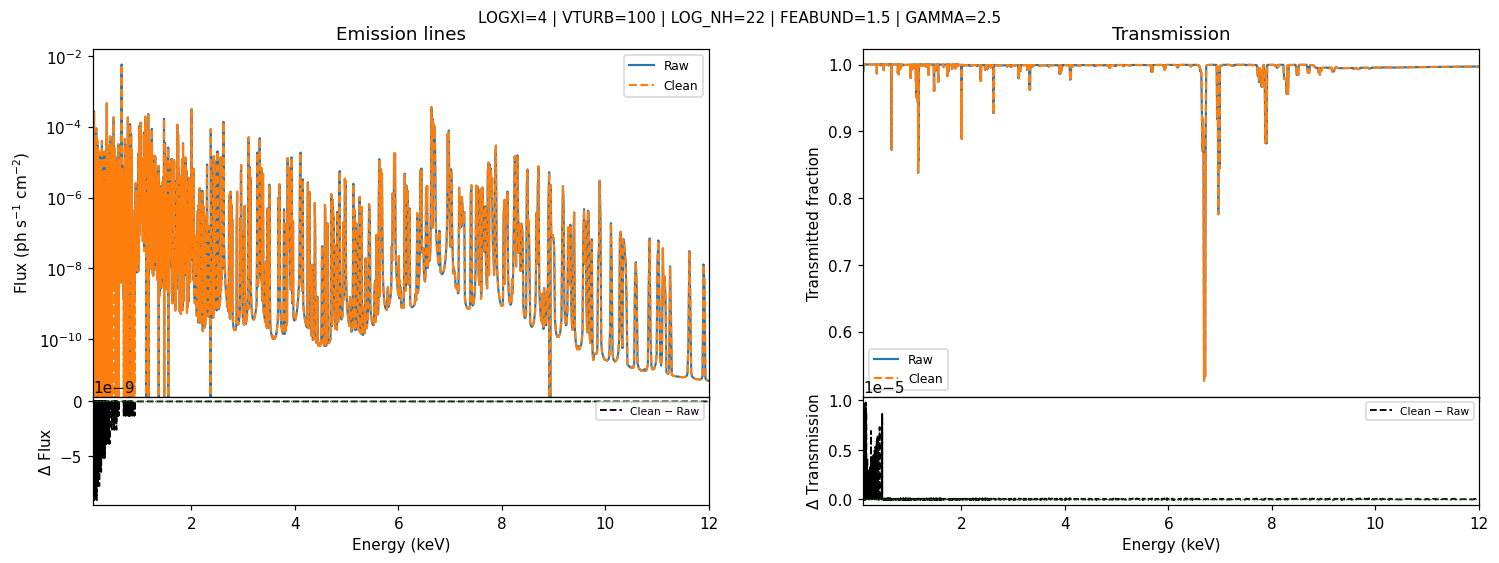

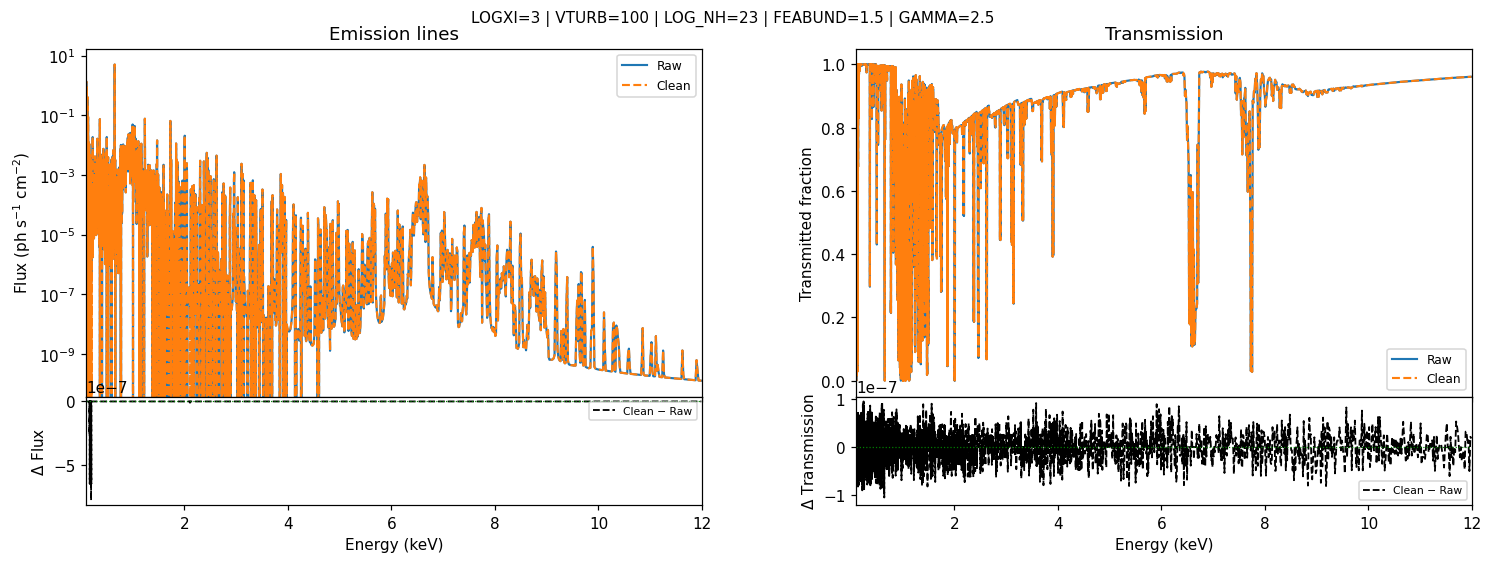

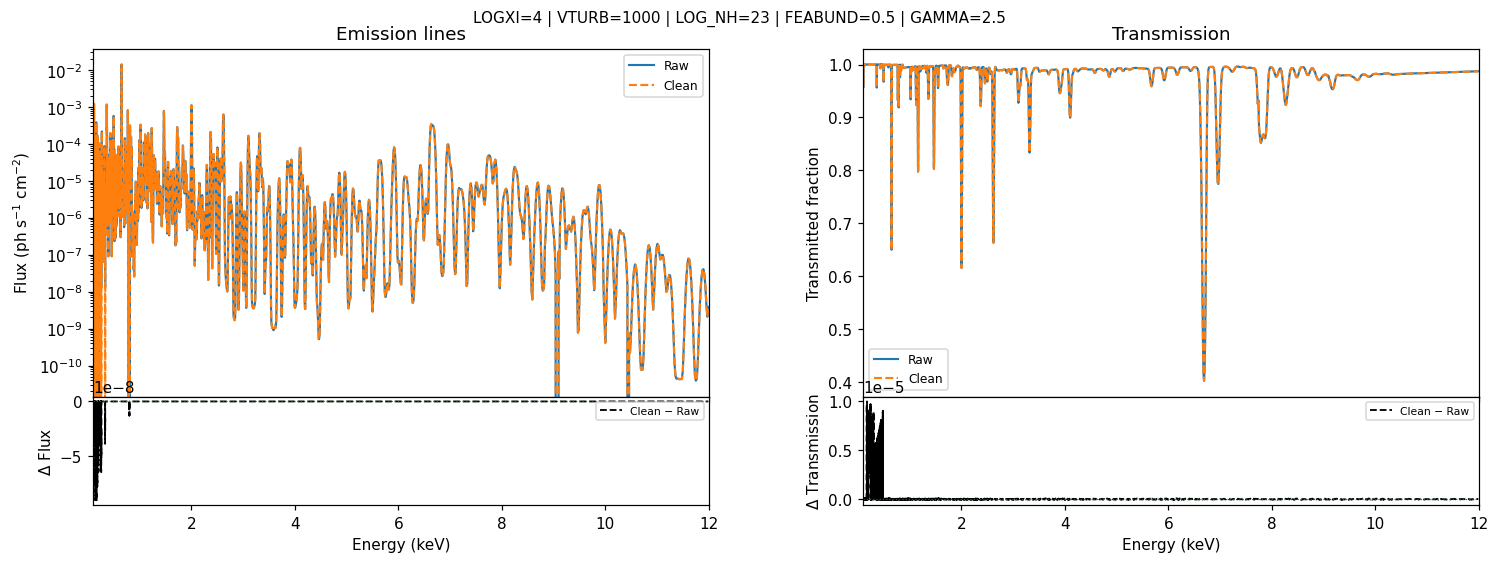

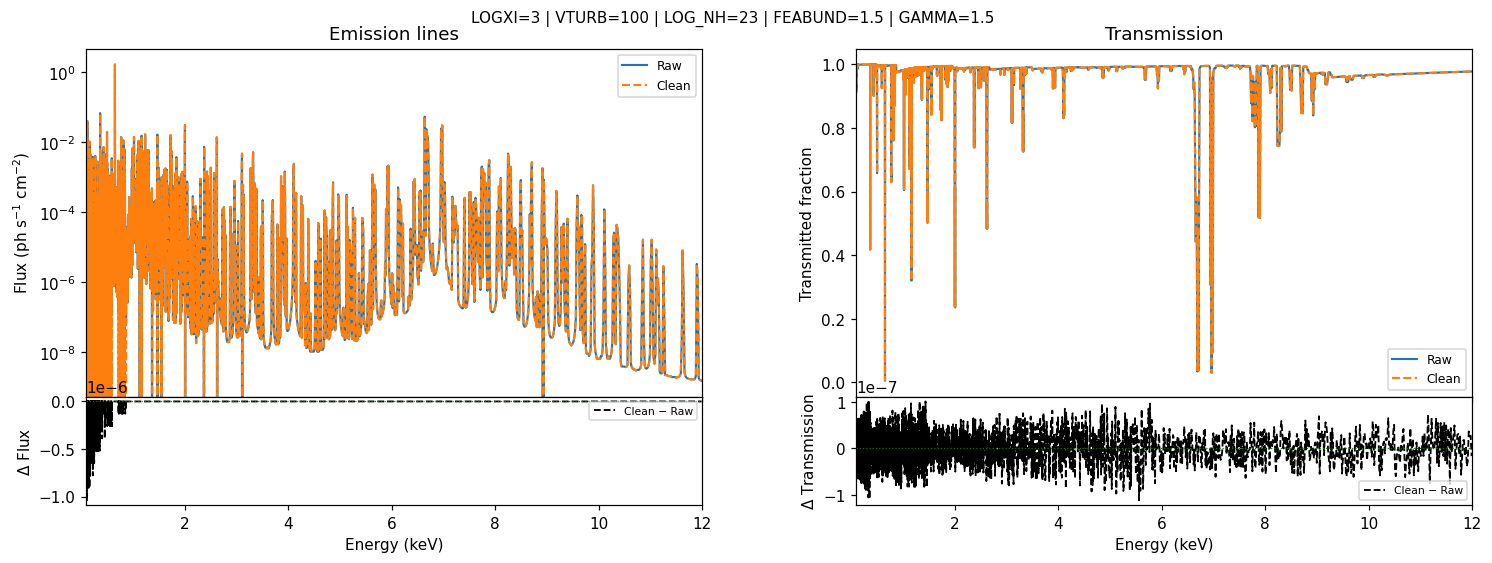

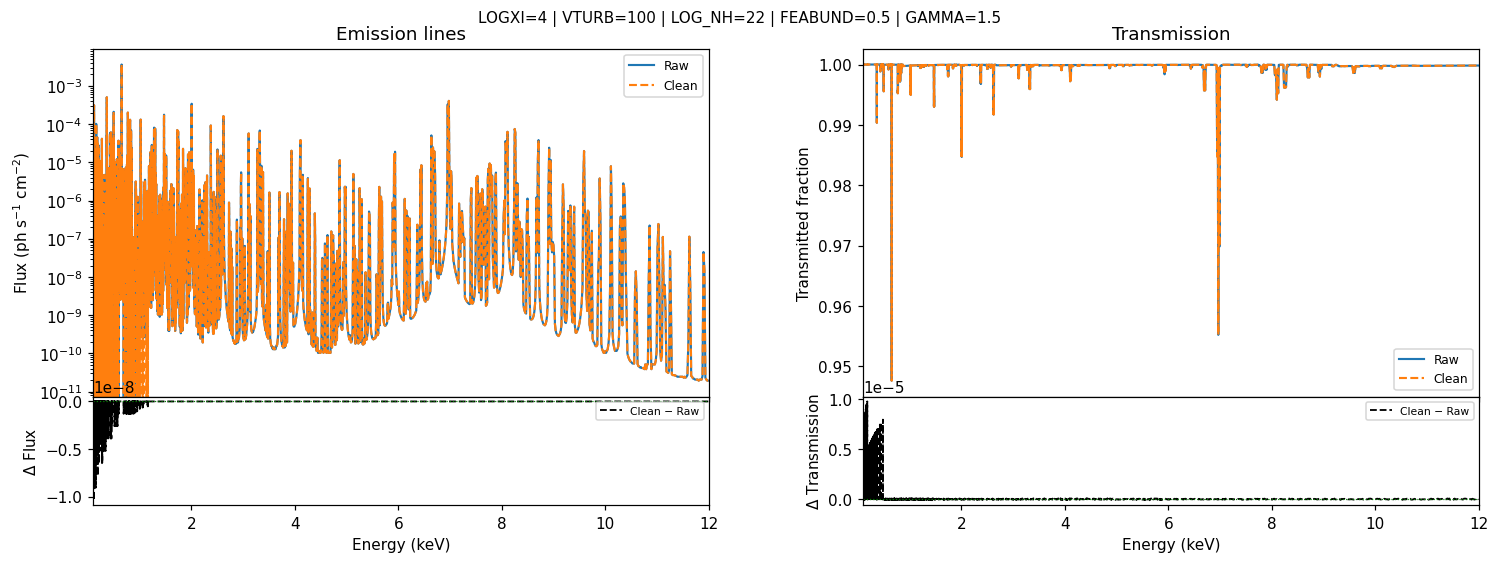

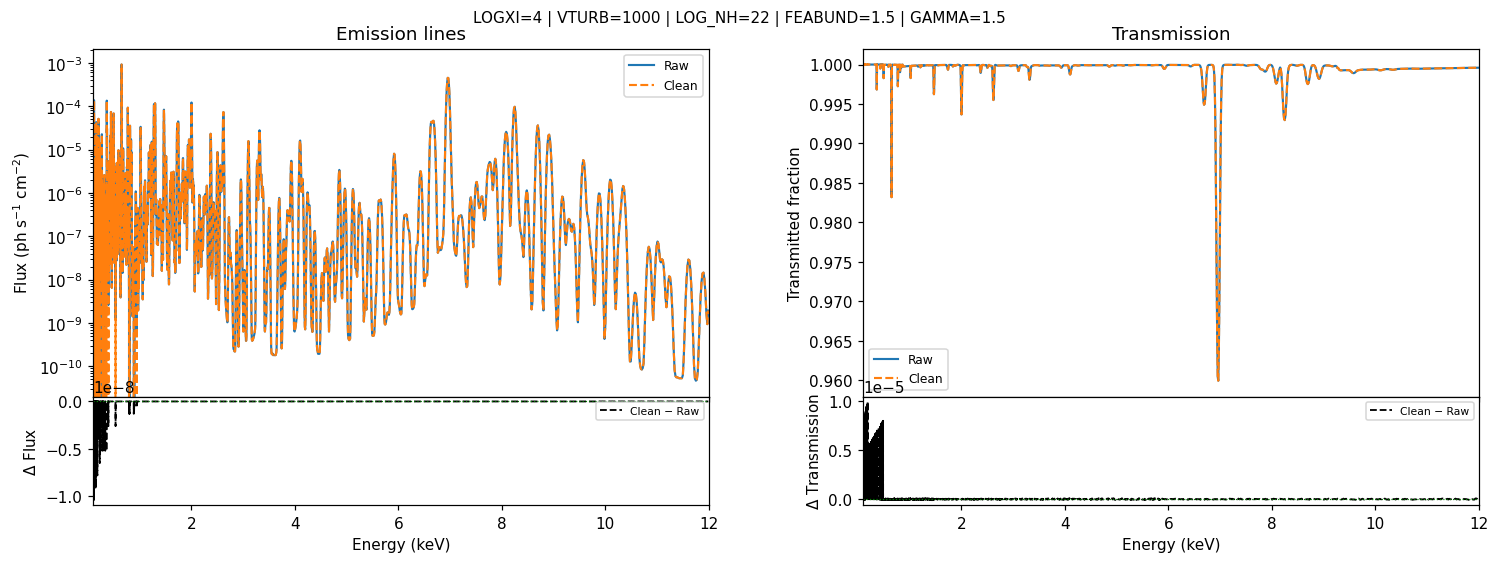

In [46]:
rng = np.random.default_rng(RANDOM_SEED)

def _all_datasets_share_energy_grid(component="emission", rtol=1e-10, atol=1e-12):
    """Return True only when every dataset has the same energy array and bin count."""
    reference_energy = np.asarray(grids[dataset_ids[0]][component]["energy"], dtype=float)
    for key in dataset_ids[1:]:
        energy = np.asarray(grids[key][component]["energy"], dtype=float)
        if energy.shape != reference_energy.shape:
            return False
        if not np.allclose(energy, reference_energy, rtol=rtol, atol=atol, equal_nan=True):
            return False
    return True

def _dataset_line_style(index):
    """Keep run identity visually consistent: first solid, second dashed."""
    styles = ["-", "--", ":", "-."]
    return styles[index % len(styles)]

def plot_random_matched_spectra(n_models=N_RANDOM_SPECTRA):
    result = matches
    n_common = len(result["keys"])
    if n_common == 0:
        raise ValueError("No common matched simulations are available.")
    n_plot = min(int(n_models), n_common)
    selected = rng.choice(n_common, size=n_plot, replace=False)
    same_energy_grid = _all_datasets_share_energy_grid("emission")
    if same_energy_grid:
        print("All datasets share the same energy grid: residual panels will be shown (direct bin-by-bin differences; no interpolation).")
    else:
        print("Datasets have different energy grids: spectra will use their native grids; residual panels will be omitted (no interpolation).")

    for plot_number, common_index in enumerate(selected):
        if same_energy_grid:
            fig, axs = plt.subplots(2, 2, figsize=(14, 5), sharex="col", gridspec_kw={"height_ratios": [3.2, 1], "hspace": 0.0, "wspace": 0.25})
            ax_emission, ax_transmission = axs[0]
            ax_emission_residual, ax_transmission_residual = axs[1]
        else:
            fig, (ax_emission, ax_transmission) = plt.subplots(1, 2, figsize=(14, 5.2), sharex=False)
            ax_emission_residual = None
            ax_transmission_residual = None
        # The matched parameter values are shown in the title:
        reference = grids[reference_id]
        reference_row_idx = result["indices"][reference_id][common_index]
        reference_params = reference["emission"]["params"].iloc[reference_row_idx]
        reference_schema = result["schemas"][dataset_ids.index(reference_id)]
        title_bits = []
        for canonical in result["canonical_names"]:
            column = reference_schema[canonical]
            title_bits.append(f"{column}={format_value(reference_params[column])}")
        fig.suptitle(" | ".join(title_bits), fontsize=10, y=0.99 if same_energy_grid else 1.02)
        component_axes = [("emission", ax_emission, ax_emission_residual, "Emission lines"),
                          ("transmission", ax_transmission, ax_transmission_residual, "Transmission")]
        for component, ax, residual_ax, panel_title in component_axes:
            plotted_spectra = {}
            for i, key in enumerate(dataset_ids):
                row_idx = result["indices"][key][common_index]
                component_data = grids[key][component]
                # Use the native energy grid of THIS dataset. No interpolation:
                energy = np.asarray(component_data["energy"], dtype=float)
                spectrum = np.asarray(component_data["spectra"][row_idx], dtype=float)
                energy_mask = (np.isfinite(energy) & (energy >= ENERGY_LOW_LIM) & (energy <= ENERGY_UP_LIM))
                if not np.any(energy_mask):
                    warnings.warn(
                        f"{grids[key]['label']} ({component}) has no energy bins "
                        f"inside {ENERGY_LOW_LIM:g}–{ENERGY_UP_LIM:g} keV; "
                        "that curve is skipped in this plot."
                    )
                    continue
                plotted_spectra[key] = (energy, energy_mask, spectrum)
                ax.plot(
                    energy[energy_mask],
                    spectrum[energy_mask],
                    color=dataset_colors[key],
                    linestyle=_dataset_line_style(i),
                    linewidth=1.4,
                    label=grids[key]["label"],
                )
            ax.set_title(panel_title)
            ax.set_xlabel("Energy (keV)")
            ax.set_xlim(ENERGY_LOW_LIM, ENERGY_UP_LIM)
            ax.legend(fontsize=8)
            if component == "emission":
                ax.set_ylabel(r"Flux (ph s$^{-1}$ cm$^{-2}$)")
                positive_lines = [
                    line.get_ydata()[np.isfinite(line.get_ydata()) & (line.get_ydata() > 0)]
                    for line in ax.lines
                ]
                if any(values.size for values in positive_lines):
                    ax.set_yscale("log")
            else:
                ax.set_ylabel("Transmitted fraction")
            if not plotted_spectra:
                ax.text(0.5, 0.5, "No spectra in selected energy interval", ha="center", va="center", transform=ax.transAxes)
            # Direct residuals are valid only when all datasets share the same grid:
            if same_energy_grid and residual_ax is not None:
                if reference_id not in plotted_spectra:
                    residual_ax.text(0.5, 0.5, "Reference spectrum unavailable", ha="center", va="center", transform=residual_ax.transAxes)
                else:
                    ref_energy, ref_mask, ref_spectrum = plotted_spectra[reference_id]
                    for i, key in enumerate(dataset_ids):
                        if key == reference_id or key not in plotted_spectra:
                            continue
                        energy, energy_mask, spectrum = plotted_spectra[key]
                        # Same-grid check guarantees bin-by-bin correspondence.
                        # The masks should therefore also select the same bins.
                        if not np.array_equal(energy_mask, ref_mask):
                            warnings.warn(f"{key} and {reference_id} energy masks differ despite the shared-grid check; residual curve was skipped.")
                            continue
                        residual = spectrum[energy_mask] - ref_spectrum[ref_mask]
                        residual_ax.plot(energy[energy_mask], residual, color="black", linestyle=_dataset_line_style(i), linewidth=1.2, 
                                         label=f"{grids[key]['label']} − {grids[reference_id]['label']}")
                    residual_ax.axhline(0, color="green", linestyle=":", linewidth=0.8)
                    residual_ax.legend(fontsize=7)
                residual_ax.set_xlim(ENERGY_LOW_LIM, ENERGY_UP_LIM)
                residual_ax.set_xlabel("Energy (keV)")
                if component == "emission":
                    residual_ax.set_ylabel(r"$\Delta$ Flux")
                else:
                    residual_ax.set_ylabel(r"$\Delta$ Transmission")
        if same_energy_grid:
            fig.subplots_adjust(left=0.08, right=0.98, bottom=0.09, top=0.92, wspace=0.25, hspace=0.08)
        else:
            fig.tight_layout()
        save_or_show(fig, f"matched_spectra_{plot_number:03d}.png")

plot_random_matched_spectra()


In [49]:
# Interactive one-parameter exploration of BOTH spectral components:

def build_parameter_lookup(component="emission"):
    canonical_names, schemas = common_physical_columns("emission")
    ref_schema = schemas[dataset_ids.index(reference_id)]
    display_names = [ref_schema[c] for c in canonical_names]
    return canonical_names, schemas, display_names

def close_values(series, value, atol=10**(-MATCH_DECIMALS)):
    vals = pd.to_numeric(series, errors="coerce").to_numpy(dtype=float)
    try:
        target = float(value)
        return np.isclose(vals, target, rtol=0, atol=atol, equal_nan=False)
    except (TypeError, ValueError):
        return (series.to_numpy() == value)

def make_one_parameter_explorer():
    canonical_names, schemas, display_names = build_parameter_lookup("emission")
    ref_frame = grids[reference_id]["emission"]["params"]
    ref_schema = schemas[dataset_ids.index(reference_id)]
    ref_rows = list(range(len(ref_frame)))
    reference_widget = widgets.Dropdown(
        options=ref_rows,
        value=ref_rows[0],
        description="Reference row:",
        layout=widgets.Layout(width="300px"),
    )
    parameter_widget = widgets.Dropdown(
        options=list(zip(display_names, canonical_names)),
        value=canonical_names[0],
        description="Vary:",
        layout=widgets.Layout(width="300px"),
    )
    mode_widget = widgets.ToggleButtons(
        options=[("All values", "all"), ("Min / middle / max", "extremes")],
        value="all",
        description="Show:",
    )

    def _plot(reference_row, parameter, plot_mode):
        reference = ref_frame.iloc[int(reference_row)]
        frozen = {
            canonical: reference[ref_schema[canonical]]
            for canonical in canonical_names
            if canonical != parameter
        }
        fig, axs = plt.subplots(2, len(dataset_ids), figsize=(6.0 * len(dataset_ids), 8.0), squeeze=False, sharex=False)
        component_rows = [("emission", 0, "Emission lines"), ("transmission", 1, "Transmission")]
        for i, key in enumerate(dataset_ids):
            # Physical parameter rows are shared across components; select rows once:
            frame = grids[key]["emission"]["params"]
            schema = schemas[dataset_ids.index(key)]
            varied_col = schema[parameter]
            mask = np.ones(len(frame), dtype=bool)
            for canonical, target in frozen.items():
                mask &= close_values(frame[schema[canonical]], target)
            positions = np.flatnonzero(mask)
            if len(positions) > 0:
                positions = sorted(positions, key=lambda p: float(frame.iloc[p][varied_col]))
                # Retain one row for each distinct value of the varied parameter:
                unique_positions = []
                seen = []
                for pos in positions:
                    value = frame.iloc[pos][varied_col]
                    duplicate = False
                    for old in seen:
                        try:
                            duplicate = np.isclose(
                                float(value), float(old), rtol=0, atol=1e-10
                            )
                        except (TypeError, ValueError):
                            duplicate = value == old
                        if duplicate:
                            break
                    if not duplicate:
                        unique_positions.append(pos)
                        seen.append(value)
                if plot_mode == "extremes" and len(unique_positions) > 3:
                    mid = len(unique_positions) // 2
                    unique_positions = [unique_positions[0], unique_positions[mid], unique_positions[-1]]
            for component, row_number, panel_title in component_rows:
                ax = axs[row_number, i]
                component_data = grids[key][component]
                energy = component_data["energy"]
                energy_mask = (np.isfinite(energy) & (energy >= ENERGY_LOW_LIM) & (energy <= ENERGY_UP_LIM))
                if len(positions) == 0:
                    ax.text(0.5, 0.5, "No simulations match\nfrozen parameters", ha="center", va="center", transform=ax.transAxes)
                else:
                    for pos in unique_positions:
                        value = frame.iloc[pos][varied_col]
                        y = component_data["spectra"][pos]
                        ax.plot(energy[energy_mask], y[energy_mask], alpha=0.85, linewidth=1.2, label=f"{varied_col}={format_value(value)}")
                    ax.legend(fontsize=7)
                if i == 0:
                    ax.set_ylabel(r"Flux (ph cm$^{-2}$ s$^{-1}$)" if component == "emission" else "Transmitted fraction")
                ax.set_title(f"{grids[key]['label']} — {panel_title}", fontsize=10)
                ax.set_xlabel("Energy (keV)")
                ax.set_xlim(ENERGY_LOW_LIM, ENERGY_UP_LIM)
                if component == "emission":
                    finite_positive = [line.get_ydata()[np.isfinite(line.get_ydata()) & (line.get_ydata() > 0)] for line in ax.lines]
                    if any(values.size for values in finite_positive):
                        ax.set_yscale("log")
        frozen_text = " | ".join(f"{ref_schema[c]}={format_value(v)}" for c, v in frozen.items())
        fig.suptitle(f"Varying {ref_schema[parameter]} | Frozen: {frozen_text}", fontsize=9)
        fig.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()
    out = widgets.interactive_output(
        _plot,
        {
            "reference_row": reference_widget,
            "parameter": parameter_widget,
            "plot_mode": mode_widget,
        },
    )
    display(widgets.VBox([reference_widget, parameter_widget, mode_widget]), out)

make_one_parameter_explorer()

Output()

In [52]:
# Interactivte comparison:

def make_nearest_model_explorer(component="emission"):
    canonical_names, schemas, display_names = build_parameter_lookup(component)
    ref_frame = grids[reference_id][component]["params"]
    ref_schema = schemas[dataset_ids.index(reference_id)]
    controls = {}
    for canonical, display_name in zip(canonical_names, display_names):
        col = ref_schema[canonical]
        values = pd.to_numeric(ref_frame[col], errors="coerce").dropna().unique()
        values = np.sort(values.astype(float))
        if len(values) == 0:
            continue
        if len(values) == 1:
            controls[canonical] = widgets.FloatText(
                value=float(values[0]), description=display_name,
                layout=widgets.Layout(width="300px")
            )
        else:
            controls[canonical] = widgets.FloatSlider(
                value=float(values[len(values)//2]),
                min=float(values.min()), max=float(values.max()),
                step=max(float(values.max()-values.min())/300, 1e-8),
                description=display_name,
                readout_format=".5g",
                continuous_update=False,
                layout=widgets.Layout(width="450px"),
            )
    def nearest_index(frame, schema, target):
        dist = np.zeros(len(frame), dtype=float)
        for canonical, target_value in target.items():
            col = frame[schema[canonical]]
            vals = pd.to_numeric(col, errors="coerce").to_numpy(dtype=float)
            scale = np.nanstd(vals)
            if not np.isfinite(scale) or scale == 0:
                scale = 1.0
            contribution = ((vals - float(target_value)) / scale) ** 2
            contribution[~np.isfinite(contribution)] = np.inf
            dist += contribution
        if not np.any(np.isfinite(dist)):
            raise ValueError("No valid nearest simulation found.")
        idx = int(np.argmin(dist))
        return idx, float(np.sqrt(dist[idx]))
    def _plot(**target):
        fig, axs = plt.subplots(1, len(dataset_ids), figsize=(6.2*len(dataset_ids), 5), squeeze=False)
        axs = axs[0]
        for i, key in enumerate(dataset_ids):
            data = grids[key][component]
            schema = schemas[dataset_ids.index(key)]
            idx, distance = nearest_index(data["params"], schema, target)
            row = data["params"].iloc[idx]
            energy = data["energy"]
            mask = (energy >= ENERGY_LOW_LIM) & (energy <= ENERGY_UP_LIM)
            axs[i].plot(energy[mask], data["spectra"][idx][mask], linewidth=1.2)
            axs[i].set_title(f"{grids[key]['label']} | row {idx} | distance={distance:.3g}")
            axs[i].set_xlabel("Energy (keV)")
            if component == "emission":
                axs[i].set_yscale("log")
                axs[i].set_ylabel(r"Flux (ph cm$^{-2}$ s$^{-1}$)")
            else:
                axs[i].set_ylabel("Transmitted fraction")
            actual = " ; ".join(f"{schema[c]}={format_value(row[schema[c]])}" for c in canonical_names)
            axs[i].text(0.5, 1.2, actual, transform=axs[i].transAxes, ha="center", va="top", fontsize=7, wrap=True)
        fig.suptitle("Nearest available simulations", fontsize=12)
        fig.tight_layout(rect=[0, 0.08, 1, 0.94])
        plt.show()

    rows = []
    control_items = list(controls.items())
    for start in range(0, len(control_items), 2):
        rows.append(widgets.HBox([widget for _, widget in control_items[start:start+2]]))
    output = widgets.interactive_output(
        _plot, {name: widget for name, widget in controls.items()}
    )
    display(Markdown(f"### Nearest {component} simulations"))
    display(widgets.VBox(rows), output)

make_nearest_model_explorer("emission")
make_nearest_model_explorer("transmission")

### Nearest emission simulations

Output()

### Nearest transmission simulations

Output()